In [1]:
import numpy as np
from matplotlib import pyplot as plt
import matplotlib.patches as patches
from mpl_toolkits.axes_grid1.inset_locator import mark_inset, zoomed_inset_axes

import primus_paleo as pp
from primus_paleo import (FluxHistory, Paleodetector, compare_scenarios, plot_exposure_timeline, plot_flux_history,
                          plot_track_groups, track_total)

SUM = pp.TOTAL_NO_LIGHT_IONS

In [2]:
mineral_name = "Olivine"

sample_area_cm2 = 1

overburden_history = {
    "initial_depth": 1.
}

h_obs_km = 1.
laschamp = {"start_time_kyr": -42., "end_time_kyr": -40., "geomagnetic_cutoff": 0.}
sn250 = {"start_time_kyr": -50., "template": {"kind": "SN", "distance_pc": 250.}}

flux_histories = {
    'base': FluxHistory(h_obs_km=h_obs_km),
    'base + Laschamp': FluxHistory(h_obs_km=h_obs_km, excursions=[laschamp]),
    'SN 250 pc': FluxHistory(h_obs_km=h_obs_km, events=[sn250]),
    'SN 250 pc + Laschamp': FluxHistory(h_obs_km=h_obs_km, events=[sn250], excursions=[laschamp]),
}

In [3]:
exposure_times = np.array([41.4, 30., 13.1, 10.96, 9.5, 8.64, 7.65])
exposure_times_err = np.array([1., 2., 0.7, 0.15, 0.5, 0.06, 0.12])
names = np.array(["Laschamp", "Lemptegy", "Come", "Dome", "Pariou", "La Vache", "Montcineyre"], dtype=str)

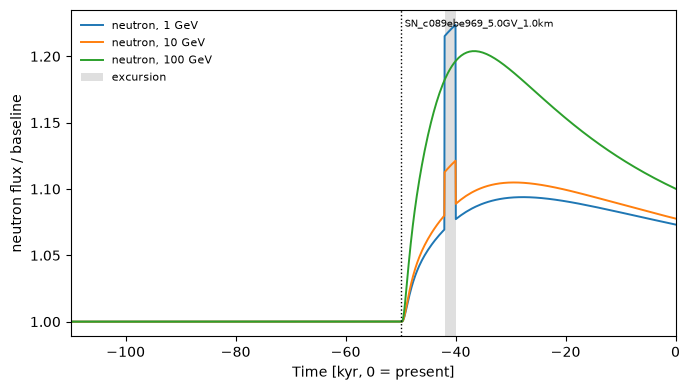

In [4]:
# The flux histories against time (neutrons at a few energies): SN onset, decay and the Laschamp excursion
fig, ax = plot_flux_history(flux_histories['SN 250 pc + Laschamp'], species='neutron')
plt.show()

In [5]:
samples = {}
for name, age in zip(names, exposure_times):
    det = Paleodetector(mineral_name, total_age_kyr=age, flux_history=flux_histories['base'],
                        overburden_history=overburden_history)
    det.verbose = 0
    histories = ['base', 'SN 250 pc'] + (['base + Laschamp', 'SN 250 pc + Laschamp'] if age > 40. else [])
    x_bins, radiogenic = det.integrate_radiogenic(nucleus='groups')
    cosmic = {h: det.integrate_all_particles(nucleus='groups', flux_history=flux_histories[h])[1] for h in histories}
    samples[name] = {'detector': det, 'age': age, 'radiogenic': radiogenic, 'cosmic': cosmic}

samples[names[0]]['detector'].describe_track_groups()

Time grid: 100 nodes over 0-41.4 kyr (100 uniform and breakpoint nodes, 0 added where the overburden or flux change; 0 flux events, 0 excursions)
Created paleo-detector Olivine, species available for computation:
  mu+        energy from 0.001 to 171.9 GeV in 90 steps
  mu-        energy from 0.001 to 171.9 GeV in 163 steps
  neutron    energy from 0.001 to 171.9 GeV in 90 steps
  proton     energy from 0.001 to 58.17 GeV in 82 steps
  nu_mu      energy from 0.05817 to 1311 GeV in 75 steps  (integrate_atmospheric_neutrinos; secondaries made in the mineral: no StdRock runs)
  anti_nu_mu energy from 0.05817 to 1311 GeV in 75 steps  (integrate_atmospheric_neutrinos; secondaries made in the mineral: no StdRock runs)
  nu_e       energy from 0.05817 to 1311 GeV in 75 steps  (integrate_atmospheric_neutrinos; secondaries made in the mineral: no StdRock runs)
  anti_nu_e  energy from 0.05817 to 1311 GeV in 75 steps  (integrate_atmospheric_neutrinos; secondaries made in the mineral: no StdRock 

100%|██████████| 5/5 [00:34<00:00,  6.91s/it]


Time grid: 100 nodes over 0-30 kyr (100 uniform and breakpoint nodes, 0 added where the overburden or flux change; 0 flux events, 0 excursions)
Created paleo-detector Olivine, species available for computation:
  mu+        energy from 0.001 to 171.9 GeV in 90 steps
  mu-        energy from 0.001 to 171.9 GeV in 163 steps
  neutron    energy from 0.001 to 171.9 GeV in 90 steps
  proton     energy from 0.001 to 58.17 GeV in 82 steps
  nu_mu      energy from 0.05817 to 1311 GeV in 75 steps  (integrate_atmospheric_neutrinos; secondaries made in the mineral: no StdRock runs)
  anti_nu_mu energy from 0.05817 to 1311 GeV in 75 steps  (integrate_atmospheric_neutrinos; secondaries made in the mineral: no StdRock runs)
  nu_e       energy from 0.05817 to 1311 GeV in 75 steps  (integrate_atmospheric_neutrinos; secondaries made in the mineral: no StdRock runs)
  anti_nu_e  energy from 0.05817 to 1311 GeV in 75 steps  (integrate_atmospheric_neutrinos; secondaries made in the mineral: no StdRock ru

100%|██████████| 5/5 [00:31<00:00,  6.24s/it]


Time grid: 100 nodes over 0-13.1 kyr (100 uniform and breakpoint nodes, 0 added where the overburden or flux change; 0 flux events, 0 excursions)
Created paleo-detector Olivine, species available for computation:
  mu+        energy from 0.001 to 171.9 GeV in 90 steps
  mu-        energy from 0.001 to 171.9 GeV in 163 steps
  neutron    energy from 0.001 to 171.9 GeV in 90 steps
  proton     energy from 0.001 to 58.17 GeV in 82 steps
  nu_mu      energy from 0.05817 to 1311 GeV in 75 steps  (integrate_atmospheric_neutrinos; secondaries made in the mineral: no StdRock runs)
  anti_nu_mu energy from 0.05817 to 1311 GeV in 75 steps  (integrate_atmospheric_neutrinos; secondaries made in the mineral: no StdRock runs)
  nu_e       energy from 0.05817 to 1311 GeV in 75 steps  (integrate_atmospheric_neutrinos; secondaries made in the mineral: no StdRock runs)
  anti_nu_e  energy from 0.05817 to 1311 GeV in 75 steps  (integrate_atmospheric_neutrinos; secondaries made in the mineral: no StdRock 

100%|██████████| 5/5 [00:25<00:00,  5.05s/it]


... (5 outputs left out)

100%|██████████| 5/5 [00:26<00:00,  5.21s/it]


Time grid: 100 nodes over 0-7.65 kyr (100 uniform and breakpoint nodes, 0 added where the overburden or flux change; 0 flux events, 0 excursions)
Created paleo-detector Olivine, species available for computation:
  mu+        energy from 0.001 to 171.9 GeV in 90 steps
  mu-        energy from 0.001 to 171.9 GeV in 163 steps
  neutron    energy from 0.001 to 171.9 GeV in 90 steps
  proton     energy from 0.001 to 58.17 GeV in 82 steps
  nu_mu      energy from 0.05817 to 1311 GeV in 75 steps  (integrate_atmospheric_neutrinos; secondaries made in the mineral: no StdRock runs)
  anti_nu_mu energy from 0.05817 to 1311 GeV in 75 steps  (integrate_atmospheric_neutrinos; secondaries made in the mineral: no StdRock runs)
  nu_e       energy from 0.05817 to 1311 GeV in 75 steps  (integrate_atmospheric_neutrinos; secondaries made in the mineral: no StdRock runs)
  anti_nu_e  energy from 0.05817 to 1311 GeV in 75 steps  (integrate_atmospheric_neutrinos; secondaries made in the mineral: no StdRock 

100%|██████████| 5/5 [00:24<00:00,  4.99s/it]

Track groups of Olivine (heavy_min_z from the composition, medium_min_z from the composition; major elements Fe, Si, Mg, O):
  heavy         Z >= Fe(26) (and spontaneous-fission fragments)
  medium_heavy  O(8) <= Z < Fe(26)
  medium_light  Li(3) <= Z < O(8)
  light         Z <= 2 (H, He)


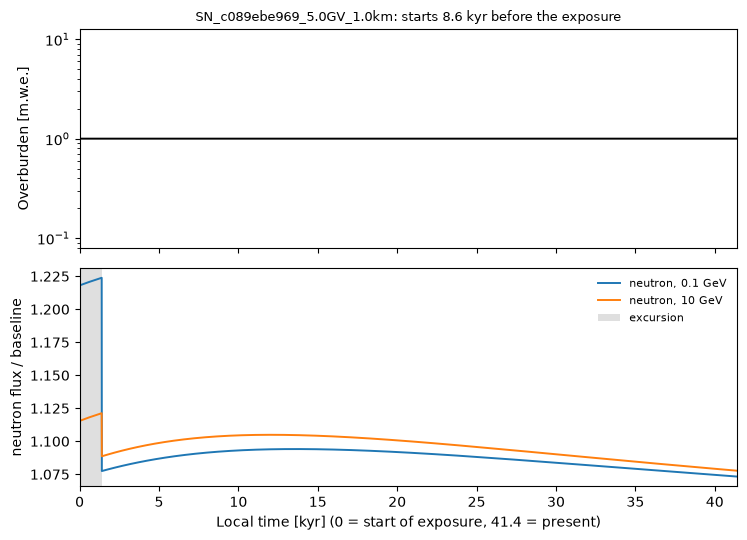

In [ ]:
fig, axes = plot_exposure_timeline(samples[names[0]]['detector'], flux_histories['SN 250 pc + Laschamp'],
                                   species='neutron', energies_gev=(0.1, 10.))
plt.show()

In [7]:
def tracks_per_mg(sample, history):
    """Total tracks per mg of one sample: cosmic rays with the given flux history plus the radiogenic background."""
    return np.sum(track_total(sample['cosmic'][history]) + track_total(sample['radiogenic']))

summed = {h: np.array([tracks_per_mg(samples[n], h) for n in names]) for h in ('base', 'SN 250 pc')}
summed_laschamp = {h: tracks_per_mg(samples[names[0]], h) for h in ('base + Laschamp', 'SN 250 pc + Laschamp')}

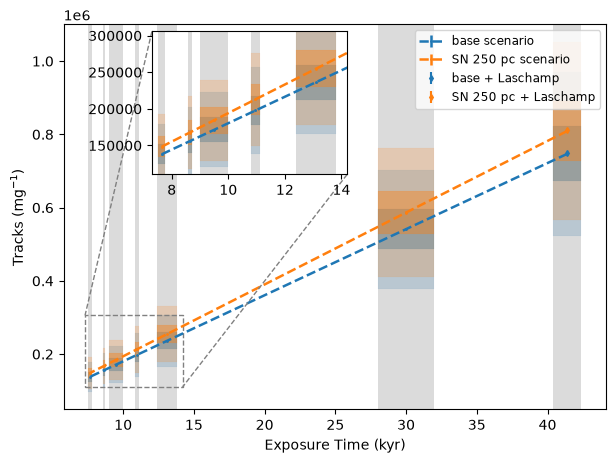

In [ ]:
def age_boxes(ax, values, color):
    """Age uncertainty of each flow (grey band) and +-10% / +-30% boxes around the predictions."""
    for age, err, v in zip(exposure_times, exposure_times_err, values):
        ax.axvspan(age - err, age + err, color='grey', alpha=0.15, linewidth=0)
        ax.add_patch(patches.Rectangle((age - err, (1 - ) * v), 2 * err, 2 * half_width * v,
                                           linewidth=0.1, facecolor=color, edgecolor=color, alpha=alpha))

def draw_series(ax):
    for h, color in (('base', 'C0'), ('SN 250 pc', 'C1')):
        ax.errorbar(exposure_times, summed[h], yerr=np.sqrt(summed[h]), label=f"{h} scenario", linewidth=1.8,
                    color=color, marker='o', markersize=1., linestyle='--', capsize=0)
        age_boxes(ax, summed[h], color)

fig, ax = plt.subplots(figsize=[7, 5])
draw_series(ax)
for h, color in (('base + Laschamp', 'C0'), ('SN 250 pc + Laschamp', 'C1')):
    ax.errorbar(exposure_times[0], summed_laschamp[h], yerr=np.sqrt(summed_laschamp[h]), label=h, color=color,
                marker='d', markersize=3, linestyle='', capsize=0)

axins = zoomed_inset_axes(ax, zoom=2., loc='upper left', bbox_to_anchor=(0.15, 0.6, 0.8, 0.4), bbox_transform=ax.transAxes)
draw_series(axins)
young = exposure_times < 15
axins.set_xlim(7.3, 14.2)
axins.set_ylim(0.8 * summed['base'][young].min(), 1.2 * summed['SN 250 pc'][young].max())
mark_inset(ax, axins, loc1=2, loc2=4, fc="none", ec="0.5", linestyle='--')

ax.set_xlabel(r"Exposure Time (kyr)")
ax.set_ylabel(r"Tracks (mg$^{-1}$)")
ax.legend(fontsize='small', loc='upper right')
plt.show()

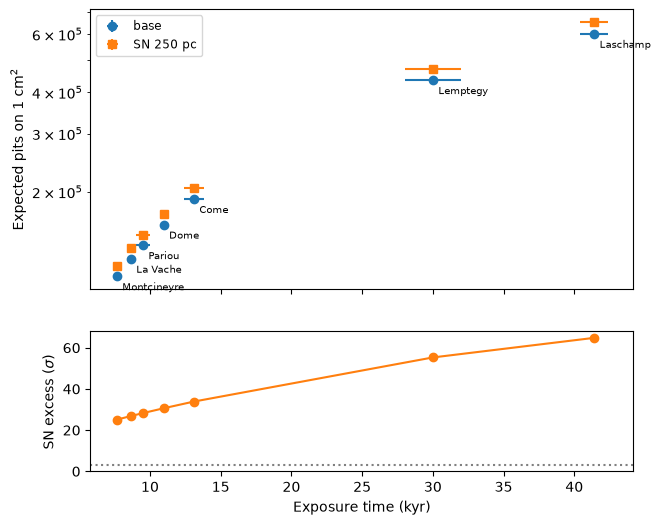

Laschamp     base     600480   SN 250 pc excess  50219.3 pits = 64.81 sigma
Lemptegy     base     435130   SN 250 pc excess  36475.5 pits = 55.30 sigma
Come         base     190007   SN 250 pc excess  14762.5 pits = 33.87 sigma
Dome         base     158968   SN 250 pc excess  12203.9 pits = 30.61 sigma
Pariou       base     137791   SN 250 pc excess  10490.8 pits = 28.26 sigma
La Vache     base     125318   SN 250 pc excess   9494.2 pits = 26.82 sigma
Montcineyre  base     110958   SN 250 pc excess   8358.6 pits = 25.09 sigma


In [9]:
# Expected etched pits (every pit: the microscope resolution is the later observation step) and the SN 250 pc excess
# over the base scenario, per flow. Each flow's spectra share one etching response, so the excess has no Monte Carlo
# noise; significance from the Poisson error of the base counts only (no systematics, no age error).
comparisons = {}
for n in names:
    sample = samples[n]
    radiogenic = sample['radiogenic']['total'][SUM]
    spectra = {h: track_total(sample['cosmic'][h]) + radiogenic for h in ('base', 'SN 250 pc')}
    comparisons[n] = compare_scenarios(spectra, 'base', sample_area_cm2, sample['detector'].config['density_g_cm3'],
                                       x_bins=x_bins)

n_base = np.array([comparisons[n]['base']['n'] for n in names])
n_excess = np.array([comparisons[n]['SN 250 pc']['excess'] for n in names])
n_sn = n_base + n_excess
significance = np.array([comparisons[n]['SN 250 pc']['significance'] for n in names])

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=[7, 6], sharex=True, gridspec_kw={'height_ratios': [2, 1]})
ax1.errorbar(exposure_times, n_base, yerr=np.sqrt(n_base), xerr=exposure_times_err, fmt='o', color='C0', label='base')
ax1.errorbar(exposure_times, n_sn, yerr=np.sqrt(n_sn), xerr=exposure_times_err, fmt='s', color='C1', label='SN 250 pc')
for name, t, n in zip(names, exposure_times, n_base):
    ax1.annotate(name, (t, n), textcoords='offset points', xytext=(4, -10), fontsize='x-small')
ax1.set_ylabel(f'Expected pits on {sample_area_cm2:g} cm$^2$')
ax1.set_yscale('log')
ax1.legend(fontsize='small')
ax2.plot(exposure_times, significance, 'o-', color='C1')
ax2.axhline(3, color='grey', linestyle=':')
ax2.set_xlabel('Exposure time (kyr)')
ax2.set_ylabel(r'SN excess ($\sigma$)')
plt.show()

for name, nb_, ne, s in zip(names, n_base, n_excess, significance):
    print(f"{name:12s} base {nb_:10.0f}   SN 250 pc excess {ne:8.1f} pits = {s:4.2f} sigma")

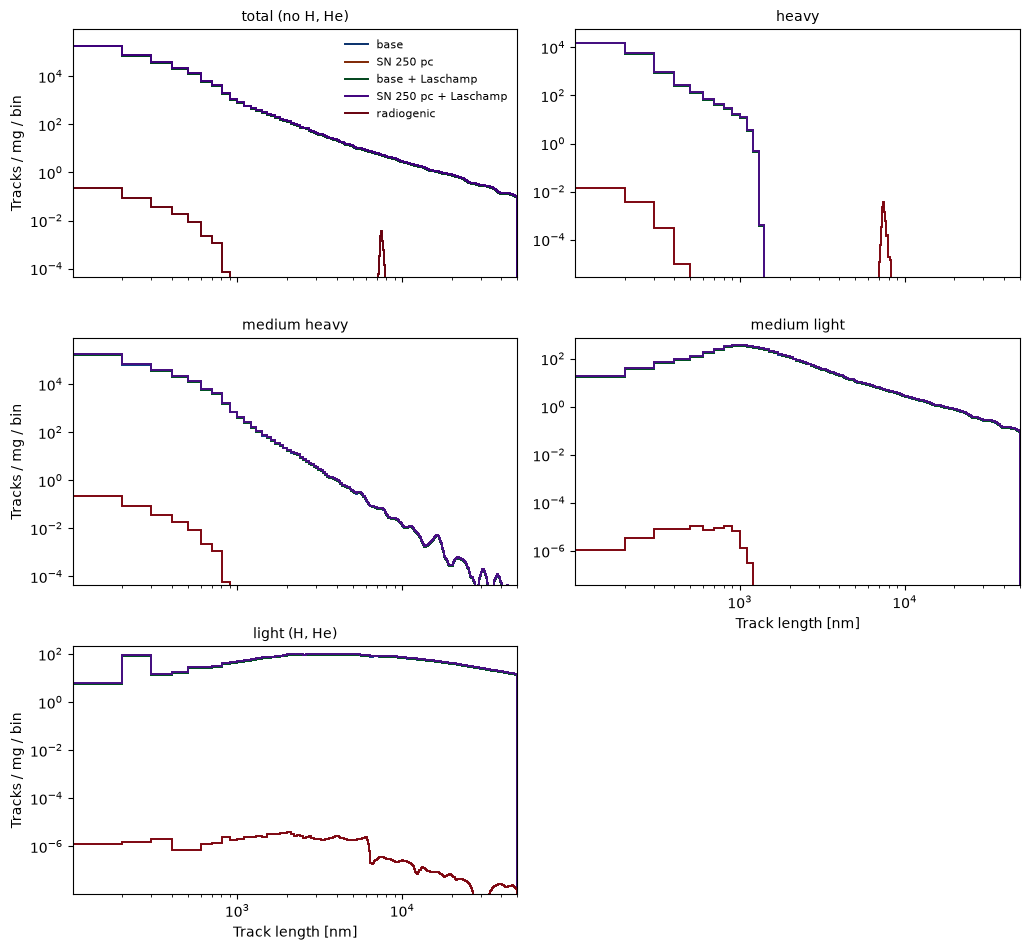

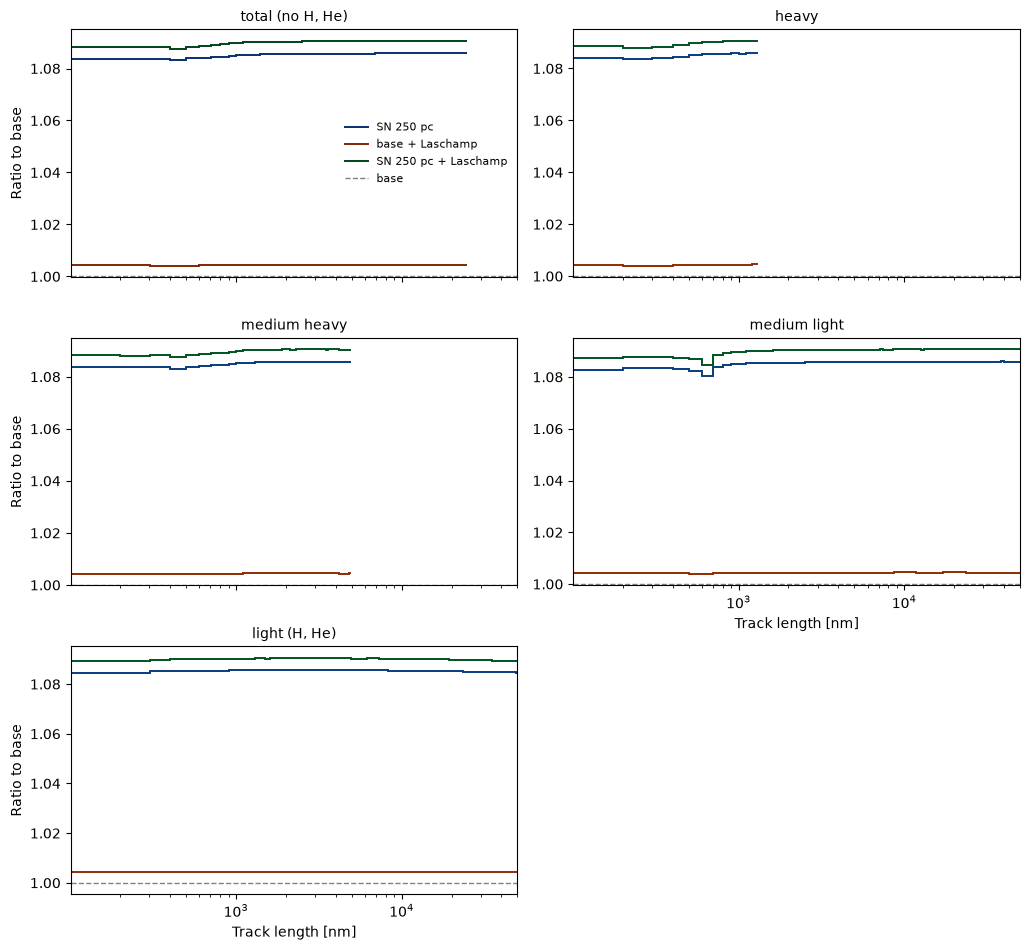

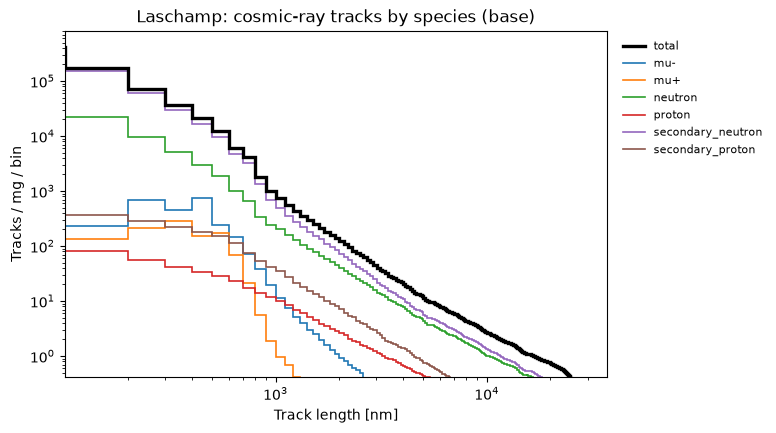

In [10]:
oldest = samples[names[0]]

# Track groups of the oldest flow: counts (log x by default for spectra this wide), radiogenic included
curves = {h: oldest['cosmic'][h]['total'] for h in oldest['cosmic']}
curves['radiogenic'] = oldest['radiogenic']['total']
fig, axes = plot_track_groups(curves, x_bins, style='panels', logy=True, y_decades=10)
plt.show()

# Where the supernova and the excursion add tracks: each scenario divided by the base one, group by group
scenarios = {h: oldest['cosmic'][h]['total'] for h in oldest['cosmic']}
fig, axes = plot_track_groups(scenarios, x_bins, style='panels', ratio_to='base')
plt.show()

# Cosmic-ray tracks by species (one curve: one colour per species)
base = oldest['cosmic']['base']
by_species = {species: v[SUM] for species, v in base.items()}
fig, ax = plot_track_groups(by_species, x_bins, style='lines', keys=[k for k in by_species if k != 'total'],
                            total='total', logy=True, y_decades=6)
ax.set_title(f"{names[0]}: cosmic-ray tracks by species (base)")
plt.show()